(save-and-trace-cubes)=
# Save, share and trace cubes

A pseudobulk analysis passes through several hands: one person or tool pools the cells,
another tests the profiles, and the results are read months later, often on another
machine. Each step should be checkable: which values did a result come from, and is the
file at hand still the one analysed? A cube answers both with three records. Its file
opens without reading its counts and checks every value it reads; its fingerprint, a
digest of every value it holds, names it; and its provenance record says how it was
made, and goes into every result computed from it. This page saves and opens a cube,
derives one from another, shows a changed file being caught, and traces a result back
to the profiles it came from. [Cube files and provenance
records](../reference/cube_files.md) describes the file and the records for programs
that read or write them.

## A cube file

{api}`read_cube` opens a cube file, here the simulated PBMC study of the
[Datasets](../reference/datasets.md) page, by reading its tables and the digests of its
values; its layers stay on disk until an analysis reads them, one cell type at a time,
and a selection of genes reads only the chunks that hold them. The fingerprint comes
from the stored digests, without a read of the layers.

In [1]:
import os
import shutil
import textwrap
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import zarr

import cytepool
from cytepool.design import Design
from cytepool.differential_expression import limma_voom
from cytepool.io import read_cube, write_cube
from cytepool.normalization import library_sizes


def megabytes(path):
    files = [path] if path.is_file() else path.rglob("*")
    return sum(file.stat().st_size for file in files if file.is_file()) / 1e6


cube = read_cube("simulated_pbmc.cube.zarr")
print(f"CytePool {cytepool.__version__}")
print(cube)
store = Path("simulated_pbmc.cube.zarr")
sizes = {"the cells": megabytes(Path("simulated_pbmc_cells.npz"))}
for name in cube.layer_names:
    sizes[f"the cube, layer {name}"] = megabytes(store / "layers" / name)
print()
for what, size in sizes.items():
    print(f"{what:<28}{size:>5.1f} MB")
print("\nfingerprint:", cube.fingerprint())

CytePool 0.1.dev61+gcd5dbe953
Cube with 24 samples x 6 groups x 2,000 features
  layers: counts (uint32, lazy), detected (uint32, lazy), log_sum (float64,
          lazy), log_sum_sq (float64, lazy), linear_sum (float64, lazy)
  filled: 144 of 144 sample x group entries have cells (100.0%)
  samples: sample_id, donor, condition, sex
  groups: group_id
  features: feature_id, symbol

the cells                    32.4 MB
the cube, layer counts        0.5 MB
the cube, layer detected      0.4 MB
the cube, layer log_sum       2.1 MB
the cube, layer log_sum_sq    2.1 MB
the cube, layer linear_sum    2.1 MB

fingerprint: sha256:554a2b5b4188308ea900cf907fa87f42d12e0458e6d5dc11525e862f3ad8a726


The counts of 19,151 cells, pooled into 144 profiles, take half a megabyte; the layers
that describe the cells take more, since their values are sums of real numbers, which
compress less. In memory, a study of 100 samples, 30 cell types and 30,000 genes needs
0.36 GB for its counts and 2.9 GB for all five layers, and an analysis of its cube file
holds one cell type at a time.

## How a cube was made

A cube is never changed in place: {api}`Cube.select`, {api}`Cube.regroup` and
{api}`Cube.collapse_samples` derive new cubes, and each adds a record of what it did to
the provenance, with the fingerprint of the cube it was applied to. Here the lymphoid
cell types are kept and the CD4 and CD8 T cells merged; {api}`write_cube` saves the
result, and {api}`Cube.history` prints its record: the source that the study's
simulation recorded, how {api}`from_cells` built the first cube, and the two operations.

In [2]:
lymphoid = cube.select(groups=["B cells", "CD4 T cells", "CD8 T cells", "NK cells"])
lymphoid = lymphoid.regroup({"T cells": ["CD4 T cells", "CD8 T cells"]})
write_cube(lymphoid, "lymphoid.cube.zarr")
opened = read_cube("lymphoid.cube.zarr")
print(opened.history())

Source, as the caller recorded it (unresolved: CytePool does not follow its
    references):
  dataset: "simulated_pbmc"
  generator: "docs/datasets.py, numpy.random.default_rng(20261026)"
  cells: "every simulated cell"
  samples: "donor_condition"
  groups: "cell type"
Built by from_cells (CytePool 0.1.dev42+g6991e63f8) from 19,151 cells:
  samples: the rows of sample_table
  groups: the rows of group_table
  features: the ids of a table
  layers: counts, detected, log_sum, log_sum_sq, linear_sum
  normalized values: each cell scaled to a total of 10,000, with library sizes
                     the total count of each cell
1. select, applied to the cube
   sha256:554a2b5b4188308ea900cf907fa87f42d12e0458e6d5dc11525e862f3ad8a726
  samples: every sample, as they were
  groups: B cells, CD4 T cells, CD8 T cells, NK cells
  features: every feature, as they were
2. regroup, applied to the cube
   sha256:bf51250542c52709ed8d3b9a2bd6ee7cc8b57987a37474a30a43e2c4b056de72
  T cells: CD4 T cells

Each operation names its input by fingerprint, so the chain can be checked link by
link: the first, the cube of the study, is the file opened above.

## A changed file is caught

The fingerprint read from a file rests on the digests stored with it, and a cube checks
each group of a layer against its digest whenever a read covers all of it. Here a copy
of the file is changed, one count more in the T cells of one sample, with zarr-python,
as a damaged copy or an edit would change it. Opening the copy and asking for its
fingerprint still succeed, since neither reads the counts; {api}`Cube.verify_fingerprint`
reads every value, and so does any analysis of the T cells, and both stop.

In [3]:
shutil.copytree("lymphoid.cube.zarr", "edited.cube.zarr")
counts = zarr.open_array("edited.cube.zarr/layers/counts", mode="r+")
counts[1, 0, 0] += 1  # the T cells of the first sample
edited = read_cube("edited.cube.zarr")
print(
    "the fingerprint, from the stored digests, as before:",
    edited.fingerprint() == opened.fingerprint(),
)
try:
    edited.verify_fingerprint()
except ValueError as error:
    message = str(error).replace(os.getcwd() + os.sep, "")
    print("\n" + textwrap.fill(f"ValueError: {message}", width=88))

the fingerprint, from the stored digests, as before: True

ValueError: group 'T cells' of the layer 'counts', read from the array at
edited.cube.zarr/layers/counts, does not match the digest stored with its cube file: the
file was changed after it was written. If the change was meant, delete the root
attribute 'digests' of the cube file (with zarr-python, for example) and open it again


## Trace a result back to its profiles

{api}`limma_voom` records in its result the fingerprint of the cube it read and, for
every cell type, the samples it fitted, in order, those it left out with the reason,
and the library size and normalization factor of each sample. From these, the
profiles of a cell type can be read back by their ids and the values of the fit
recomputed.

In [4]:
design = Design(
    opened.samples,
    "~ donor + condition",
    levels={"condition": ["ctrl", "stim"]},
    contrasts={"stim_vs_ctrl": "conditionstim"},
)
result = limma_voom(opened, design)
record = result.provenance
print(
    "computed from this cube file:",
    record["cube"]["fingerprint"] == read_cube("lymphoid.cube.zarr").fingerprint(),
)

table = result.table("T cells", "stim_vs_ctrl")
fit = next(group for group in record["groups"] if group["group_id"] == "T cells")
used = result.samples.filter(
    (result.samples["group_id"] == "T cells") & result.samples["used"]
)
profiles = opened.select(
    samples=fit["samples"], groups="T cells", features=table["feature_id"]
)
counts = profiles.layer("counts", "T cells")
print(
    f"T cells: {len(fit['samples'])} profiles fitted, left out: {fit['left_out'] or 'none'}"
)
print(
    "library sizes as fitted:",
    np.array_equal(library_sizes(counts), used["library_size"]),
)
# The log-CPM values that voom computes, from the effective library sizes.
size = used["library_size"] * used["norm_factor"]
log_cpm = np.log2((counts + 0.5) / (size[:, np.newaxis] + 1) * 1e6)
print(
    "average log2 CPM as in the table:",
    np.allclose(log_cpm.mean(axis=0), table["average_log2_cpm"], rtol=1e-12),
)

computed from this cube file: True
T cells: 24 profiles fitted, left out: none
library sizes as fitted: True
average log2 CPM as in the table: True


The profiles read back give the library sizes that entered the fit, and their log-CPM
values the average expression of every gene in the table. They can be drawn too: here
the gene with the smallest p-value, in every sample that entered its test, the two
samples of each donor joined by a line.

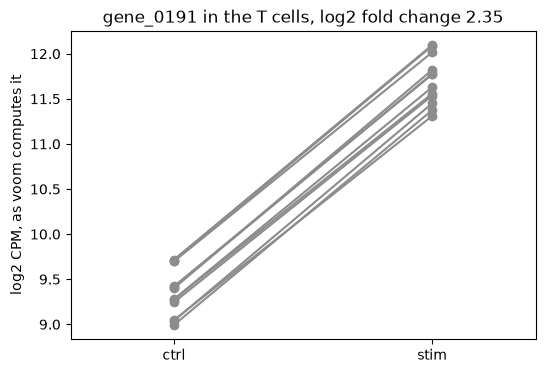

In [5]:
gene = int(np.argmin(table["p_value"]))
donor = profiles.samples["donor"]
figure, ax = plt.subplots(figsize=(6, 4))
for name in np.unique(donor):
    ax.plot(["ctrl", "stim"], log_cpm[donor == name, gene], color="0.55", marker="o")
ax.set_xlim(-0.4, 1.4)
ax.set_ylabel("log2 CPM, as voom computes it")
ax.set_title(
    f"{table['feature_id'][gene]} in the T cells, "
    f"log2 fold change {table['log2_fold_change'][gene]:.2f}"
)
plt.show()

## What CytePool can and cannot resolve

- **It can** go from any number of a result to its cell type, contrast and gene, to the
  samples of that fit and those left out with the reason, and to the profiles of the
  cube that entered it, by their ids. It can tell whether a cube at hand is the one
  analysed, by its fingerprint, and check, by reading it, that every value still
  matches its digest. The record also holds the design and the settings of the fit,
  and how the cube was made.
- **It cannot** find a cube from its fingerprint, which names the cube's values, not
  where they are stored: keep the cube file with the results.
- **It cannot** follow the source record, which CytePool keeps as the tool that pooled
  the cells wrote it; what it refers to, such as a dataset or a selection of cells,
  needs that tool.
- **It cannot** go from a cube back to the cells, since a cube holds sums over cells:
  keep the cells too.

## Choices

- **Compression.** {api}`write_cube` compresses with gzip by default (level 4);
  `compression="zstd"` uses Zstandard, on Python 3.14 or newer, and `compression=None`
  stores the values uncompressed.
- **Checking a copy.** {api}`Cube.verify_fingerprint` reads every value of a file and
  checks it against its digest: run it after copying a file, or before reporting
  results computed from one.
- **Memory.** A cube from {api}`read_cube` reads its layers as an analysis needs them;
  {api}`Cube.to_memory` reads them all at once, when they fit in memory and are read
  many times.
- **Meant changes.** Derive a new cube with {api}`Cube.select`, {api}`Cube.regroup` or
  {api}`Cube.collapse_samples` and save it, so that its record says what changed.
- **Records of results.** A result's `provenance` is plain JSON: save it with the
  tables, for example with `json.dump`.
- **Other tools.** Any Zarr v3 reader opens a cube file. [Export a cube from another
  tool](export_cubes.ipynb) builds one from sums that another tool computed, and [Work
  with AnnData and MuData](anndata_and_mudata.ipynb) converts cubes for scanpy,
  decoupler and LIANA.